# Vision v1: risky values in photos taken at home

The gate so far reads text. A camera at home also sees letters, cards and bank statements. This notebook asks how much of the text gate carries over to photos.

- **Photos:** BIV-Priv-Seg query set (WACV 2025), 1,056 photos taken at home by people who are blind or have low vision, with props in place of their own documents. Downloaded to `Dataset/BIV-Priv/`.
- **Labels:** the dataset marks object types (card, letter, receipt). Those are not the gate's labels. Each photo is labelled again with the eval v1 rules (`gate.D_PII`, `gate.D_CRED`): is a value legible that identifies a person or gives access. A VLM writes a draft; a person checked the first 157 photos (section 5).
- **Photos without a marked object (196):** checked by eye (`Dataset/BIV-Priv/review/unannotated.json`). 170 are negatives; 26 black frames hold nothing and are left out.
- **Split:** validation and test, half each, grouped so that photos of the same prop stay on one side. Choices are made on validation and test is reported once.
- **Orientation:** many photos are sideways or upside down. Every orientation method runs on both splits, and the MVP uses the one chosen on validation.
- Code: `scripts/vision.py` (shared with the MVP). Outputs: `out/vision_v1/`.

In [1]:
import json, os, sys, time, collections
from concurrent.futures import ThreadPoolExecutor
import pandas as pd
sys.path.insert(0, "scripts")
import gate as G
import vision as V

OUT = G.ROOT + "out/vision_v1/"
os.makedirs(OUT, exist_ok=True)
ann = json.load(open(V.ROOT + "biv-priv-seg-query.json"))
CAT = {c["id"]: c["name"] for c in ann["categories"]}
FILES = sorted((i["file_name"] for i in ann["images"]), key=lambda f: int(f.split(".")[0]))
OBJ = collections.defaultdict(list)
for a in ann["annotations"]:
    OBJ[a["file_name"]].append(CAT[a["category_id"]])
UN = json.load(open(V.ROOT + "review/unannotated.json"))
PHOTOS = [f for f in FILES if f not in UN["no_content_black_frames"]]
LIMIT = None  # smoke test (done 2026-11-11): ["268.jpeg", "572.jpeg", "363.jpeg", "573.jpeg", "583.jpeg"]
SUB = PHOTOS if LIMIT is None else LIMIT
print(f"{len(FILES)} photos, {len(PHOTOS)} kept, {sum(f in OBJ for f in PHOTOS)} with a marked object; running {len(SUB)}")

1056 photos, 1030 kept, 860 with a marked object; running 1030


## 1. On-device OCR in four orientations

Three engines, each run on the photo turned 0, 90, 180 and 270 degrees. Word boxes are mapped back to the upright photo.
- `tesseract3`: Tesseract 5, automatic page layout (psm 3).
- `tesseract11`: Tesseract 5, sparse text (psm 11), the mode meant for text in scenes.
- `apple`: Apple Vision through `ocrmac`, accurate mode.

Four ways to use the runs (`vision.orient`):
- `none`: the photo as it is.
- `osd`: the angle from Tesseract's orientation detection (psm 0); 0 when it cannot decide.
- `best4`: the angle whose words have the highest summed confidence.
- `union4`: the words of all four angles together.

In [2]:
def run_ocr(engine, workers=4):
    path = OUT + f"ocr_{engine}.jsonl"
    done = {json.loads(l)["file"] for l in open(path)} if os.path.exists(path) else set()
    todo = [f for f in SUB if f not in done]
    t = time.time()
    def one(f):
        img = V.load(V.ROOT + "query_images/" + f)
        return {"file": f, "runs": {a: V.ENGINES[engine](img, a) for a in V.ANGLES}}
    with open(path, "a") as fo, ThreadPoolExecutor(workers) as ex:
        for r in ex.map(one, todo):
            fo.write(json.dumps(r) + "\n")
    print(f"{engine}: {len(todo)} new in {time.time() - t:.0f}s")
    return {d["file"]: {int(a): [tuple(w) for w in ws] for a, ws in d["runs"].items()} for d in map(json.loads, open(path))}


def run_osd(workers=4):
    path = OUT + "osd.jsonl"
    done = {json.loads(l)["file"] for l in open(path)} if os.path.exists(path) else set()
    todo = [f for f in SUB if f not in done]
    with open(path, "a") as fo, ThreadPoolExecutor(workers) as ex:
        for f, a in zip(todo, ex.map(lambda f: V.osd(V.load(V.ROOT + "query_images/" + f)), todo)):
            fo.write(json.dumps({"file": f, "angle": a}) + "\n")
    return {d["file"]: d["angle"] for d in map(json.loads, open(path))}


OSD = run_osd()
OCR = {e: run_ocr(e, workers=1 if e == "apple" else 4) for e in V.ENGINES}
print(f"OSD decided an angle for {sum(OSD[f] is not None for f in SUB)} of {len(SUB)} photos")

tesseract3: 0 new in 0s


tesseract11: 0 new in 0s


apple: 0 new in 0s
OSD decided an angle for 394 of 1030 photos


In [3]:
rows = []
for e, runs in OCR.items():
    for m in V.METHODS:
        words = [V.orient(runs[f], m, OSD[f]) for f in SUB]
        rows.append({"engine": e, "method": m, "words per photo": sum(map(len, words)) / len(SUB),
                     "photos with any word": sum(bool(w) for w in words) / len(SUB)})
pd.DataFrame(rows).round(2)

,engine,method,words per photo,photos with any word
0,tesseract3,none,20.06,0.34
1,tesseract3,osd,20.19,0.34
2,tesseract3,best4,23.15,0.42
3,tesseract3,union4,70.77,0.43
4,tesseract11,none,75.67,0.96
5,tesseract11,osd,75.97,0.96
6,tesseract11,best4,85.07,0.97
7,tesseract11,union4,270.77,0.97
8,apple,none,14.89,0.64
9,apple,osd,14.90,0.63


In [4]:
for f in SUB[:0] if LIMIT is None else SUB:  # per-photo print only in the smoke test
    print(f, OBJ.get(f), "| OSD", OSD[f])
    for e in OCR:
        print(f"  {e:12s}", V.text_of(V.orient(OCR[e][f], "best4"))[:140].replace("\n", " | "))

## 2. Label drafts

Claude Opus 5.5 (`anthropic/claude-opus-5.5`) reads each full-size photo and lists the legible values that identify a person or give access, then applies the eval v1 rules. It is not one of the models under test. A person checked the first 157 drafts (section 5).

**Draft v2.** The first pass (v1) judged many props as not real ("novelty card", "sample", "fictional name"). Eval v1 counts generated values as real, so v2 adds one sentence: the props stand in for real documents, judge every value as if it were real. Photos are drafted again with v2 when the v1 draft discounted a value as fake, listed an identifying or access value without a risk, or gave no readable answer. Amazon Bedrock stopped three photos with its content filter; those go to another zero-retention provider.

In [5]:
import re

FAKEISH = re.compile(r"novelty|\bprops?\b|fictional|sample|fake|specimen|placeholder|not real|invalid|implausible|dummy|mock|template|example", re.I)
RISK_KINDS = {"card", "bank_account", "password", "pin", "api_key", "id", "phone", "email", "address", "dob"}


def needs_v2(d):
    x = d["draft"]
    if x is None:
        return True
    if d.get("version", 1) == V.DRAFT_VERSION:
        return False
    return bool(FAKEISH.search(x.get("note", ""))) or (not (x["pii"] or x["credential"]) and any(v["kind"] in RISK_KINDS for v in x["values"]))


def run_drafts(workers=2):  # 8 in flight hit OpenRouter's credit reservation twice
    path = OUT + "drafts.jsonl"
    last = {d["file"]: d for d in map(json.loads, open(path))} if os.path.exists(path) else {}  # the last line per photo wins
    todo = [f for f in SUB if f not in last or needs_v2(last[f])]
    t = time.time()
    def one(f):
        raw, parsed, cost = V.draft(V.load(V.ROOT + "query_images/" + f))
        if parsed is None and "content_filter" in raw:
            raw, parsed, cost2 = V.draft(V.load(V.ROOT + "query_images/" + f), avoid=["Amazon Bedrock"])
            cost = (cost or 0) + (cost2 or 0)
        return {"file": f, "raw": raw, "draft": parsed, "cost": cost, "model": V.DRAFT_MODEL, "version": V.DRAFT_VERSION}
    with open(path, "a") as fo, ThreadPoolExecutor(workers) as ex:
        for r in ex.map(one, todo):
            fo.write(json.dumps(r, ensure_ascii=False) + "\n")
    print(f"drafts: {len(todo)} new in {time.time() - t:.0f}s")
    return {d["file"]: d for d in map(json.loads, open(path))}


DR = run_drafts()
bad = [f for f in SUB if DR[f]["draft"] is None]
spent = sum(json.loads(l)["cost"] or 0 for l in open(OUT + "drafts.jsonl"))
print("unreadable answers:", bad, "| drafts by version:", collections.Counter(DR[f].get("version", 1) for f in SUB), "| all draft calls $", round(spent, 2))
for f in SUB if LIMIT else []:  # per-photo print only in the smoke test
    d = DR[f]["draft"] or {}
    print(f, OBJ.get(f), "| pii", d.get("pii"), "credential", d.get("credential"), "|", d.get("note"))
    print("   ", [(v["text"], v["kind"]) for v in d.get("values", [])])
# drafts by dataset object type (a photo can hold several objects; photos without one are "none")
rows = [{"object": o, "pii": bool((DR[f]["draft"] or {}).get("pii")), "credential": bool((DR[f]["draft"] or {}).get("credential"))}
        for f in SUB for o in (OBJ.get(f) or ["none"])]
pd.DataFrame(rows).groupby("object").agg(photos=("pii", "size"), pii=("pii", "sum"), credential=("credential", "sum"))

drafts: 0 new in 0s
unreadable answers: [] | drafts by version: Counter({1: 872, 2: 158}) | all draft calls $ 22.0


,photos,pii,credential
object,,,
bank_statement,65,34,25
bills_or_receipt,57,1,0
business_card,71,44,0
condom_box,30,0,0
condom_with_plastic_bag,66,0,0
credit_or_debit_card,63,1,39
doctors_prescription,62,52,0
empty_pill_bottle,48,17,0
letters_with_address,60,28,0


## 3. Review page

`Dataset/BIV-Priv/review/labels.html` shows each photo with its draft: PII and credential ticks and the legible values, one per line as `kind | text`. Edits stay in the browser; the save button downloads `labels_checked.json`, which goes into `Dataset/BIV-Priv/review/`. The page and the thumbnails stay local (not in git).

In [6]:
REV = V.ROOT + "review/"
os.makedirs(REV + "thumbs", exist_ok=True)
for f in SUB:  # small copies for the page; the full photo opens on click
    if not os.path.exists(REV + "thumbs/" + f):
        im = V.load(V.ROOT + "query_images/" + f)
        im.thumbnail((640, 640))
        im.save(REV + "thumbs/" + f, quality=85)

items = []
for f in SUB:
    d = DR[f]["draft"] or {"values": [], "pii": False, "credential": False, "note": "(no readable draft)"}
    items.append({"file": f, "objects": OBJ.get(f, []), "pii": bool(d["pii"]), "credential": bool(d["credential"]),
                  "values": "\n".join(f'{v["kind"]} | {v["text"]}' for v in d["values"]), "note": d.get("note", "")})

PAGE = """<!doctype html><html><head><meta charset="utf-8"><title>Photo labels</title><style>
body{font:14px system-ui,sans-serif;margin:0;background:#f6f6f4;color:#222}
header{position:sticky;top:0;background:#fff;border-bottom:1px solid #ddd;padding:8px 16px;display:flex;gap:12px;align-items:center;flex-wrap:wrap;z-index:1}
.card{display:flex;gap:16px;background:#fff;margin:12px 16px;padding:12px;border-radius:8px;border:2px solid #ddd}
.card{flex-wrap:wrap}.card.done{border-color:#7a7}.card img{width:300px;max-width:100%;height:auto;cursor:zoom-in;border-radius:4px}
.side{min-width:260px}
.side{flex:1;display:flex;flex-direction:column;gap:6px}textarea{width:100%;min-height:110px;font:13px ui-monospace,monospace}
.meta{color:#666;font-size:12px}label{margin-right:14px}button{padding:4px 10px}
</style></head><body><header>
<b>Photo labels</b><span id="count"></span>
<select id="filter"><option value="todo">Not checked</option><option value="risky">Draft says PII or credential</option><option value="all">All</option></select>
<button onclick="exportJSON()">Save labels (download JSON)</button>
<label>Load saved <input type="file" accept=".json" onchange="importJSON(this)"></label>
<span class="meta">Rule: PII = full name with contact, address, date of birth, ID or health detail, or an ID alone. Credential = a value that gives access (card number, account number, password, PIN, key). One value per line: kind | text, copied as printed. Tick "Checked" when the photo is done.</span>
</header><div id="list"></div><script>
const ITEMS = __ITEMS__;
const KEY = "biv-priv-labels-v1";
let saved = {}; try { saved = JSON.parse(localStorage.getItem(KEY) || "{}"); } catch (e) {}
const get = it => saved[it.file] || {pii: it.pii, credential: it.credential, values: it.values, checked: false};
function store() { try { localStorage.setItem(KEY, JSON.stringify(saved)); } catch (e) {} count(); }
function set(f, k, v) { const it = ITEMS.find(x => x.file == f); saved[f] = Object.assign(get(it), {[k]: v}); store(); }
function count() { document.getElementById("count").textContent = Object.values(saved).filter(s => s.checked).length + " / " + ITEMS.length + " checked"; }
function render() {
  const m = document.getElementById("filter").value, L = document.getElementById("list"); L.innerHTML = "";
  for (const it of ITEMS) {
    const s = get(it);
    if (m == "todo" && s.checked) continue;
    if (m == "risky" && !(it.pii || it.credential)) continue;
    const c = document.createElement("div"); c.className = "card" + (s.checked ? " done" : "");
    c.innerHTML = `<a href="../query_images/${it.file}" target="_blank"><img loading="lazy" src="thumbs/${it.file}"></a><div class="side">
      <div><b>${it.file}</b> <span class="meta">dataset objects: ${it.objects.join(", ") || "none"}</span></div>
      <div class="meta">draft note: ${it.note.replace(/</g, "&lt;")}</div>
      <div><label><input type="checkbox" data-k="pii" ${s.pii ? "checked" : ""}> PII</label><label><input type="checkbox" data-k="credential" ${s.credential ? "checked" : ""}> Credential</label><label><input type="checkbox" data-k="checked" ${s.checked ? "checked" : ""}> Checked</label></div>
      <textarea data-k="values"></textarea></div>`;
    c.querySelector("textarea").value = s.values;
    c.querySelectorAll("[data-k]").forEach(e => e.onchange = () => { set(it.file, e.dataset.k, e.type == "checkbox" ? e.checked : e.value); if (e.dataset.k == "checked") c.classList.toggle("done", e.checked); });
    L.appendChild(c);
  }
}
function exportJSON() {
  const out = ITEMS.map(it => Object.assign({file: it.file}, get(it)));
  const a = document.createElement("a"); a.href = URL.createObjectURL(new Blob([JSON.stringify(out, null, 1)], {type: "application/json"}));
  a.download = "labels_checked.json"; a.click();
}
function importJSON(inp) { inp.files[0].text().then(t => { for (const r of JSON.parse(t)) saved[r.file] = r; store(); render(); }); }
document.getElementById("filter").onchange = render; count(); render();
</script></body></html>"""
open(REV + "labels.html", "w").write(PAGE.replace("__ITEMS__", json.dumps(items, ensure_ascii=False)))
print(f"review page: {REV}labels.html ({len(items)} photos, {sum(i['pii'] or i['credential'] for i in items)} drafted as risky)")


review page: /Users/jhtae/PaperReview/AI_Gatekeeper/experiments/Dataset/BIV-Priv/review/labels.html (1030 photos, 307 drafted as risky)


## 4. Harmful flag on photo text (Granite Guardian)

The MVP first ran Granite Guardian on the text read from a photo, and a business card set off a family alert. BIV-Priv holds no harmful content, so every flag here is a false one. Same call as the MVP (`mvp/gateway.py` `harmful`, risk "harm", flag at p ≥ 0.5) on `"Photo: "` + the Apple Vision text (best of four), the MVP's input. Photos with no text are skipped, as in the MVP. Result: the MVP no longer flags photos as harmful (2026-11-11); text in view, such as a page of a novel, is not what the person said.

In [7]:
sys.path.insert(0, "../mvp")
import gateway as GW

path = OUT + "granite_harm.jsonl"
done = {json.loads(l)["file"] for l in open(path)} if os.path.exists(path) else set()
todo = [f for f in SUB if f not in done and V.text_of(V.orient(OCR["apple"][f], "best4")).strip()]
t = time.time()
with open(path, "a") as fo:
    for f in todo:
        fo.write(json.dumps({"file": f, "p_harm": GW.harmful("Photo: " + V.text_of(V.orient(OCR["apple"][f], "best4")))}) + "\n")
print(f"granite: {len(todo)} new in {time.time() - t:.0f}s")
PH = {d["file"]: d["p_harm"] for d in map(json.loads, open(path))}
risky = lambda f: bool((DR[f]["draft"] or {}).get("pii") or (DR[f]["draft"] or {}).get("credential"))
rows = [{"photos": name, "with text": len(fs), "flagged": sum(PH[f] >= 0.5 for f in fs), "rate": sum(PH[f] >= 0.5 for f in fs) / max(len(fs), 1)}
        for name, fs in [("all", [f for f in SUB if f in PH]), ("drafted risky", [f for f in SUB if f in PH and risky(f)]),
                         ("drafted safe", [f for f in SUB if f in PH and not risky(f)])]]
print(f"{len(SUB) - len(PH)} photos have no Apple Vision text and are skipped")
pd.DataFrame(rows).round(3)

granite: 0 new in 0s
335 photos have no Apple Vision text and are skipped


,photos,with text,flagged,rate
0,all,695,330,0.475
1,drafted risky,303,183,0.604
2,drafted safe,392,147,0.375


In [8]:
by_obj = [{"object": o, "flagged": PH[f] >= 0.5} for f in SUB if f in PH for o in (OBJ.get(f) or ["none"])]
pd.DataFrame(by_obj).groupby("object").agg(photos=("flagged", "size"), flagged=("flagged", "sum")).assign(rate=lambda d: (d.flagged / d.photos).round(2))

,photos,flagged,rate
object,,,
bank_statement,53,12,0.23
bills_or_receipt,53,20,0.38
business_card,63,38,0.60
condom_box,26,12,0.46
condom_with_plastic_bag,55,18,0.33
credit_or_debit_card,56,42,0.75
doctors_prescription,58,48,0.83
empty_pill_bottle,37,23,0.62
letters_with_address,49,31,0.63


## 5. Labels and split

- **Labels:** the first 157 photos by file number (0 to 160) were checked by hand on the review page (`review/labels_checked.json`); the other 873 keep the Claude Opus 5.5 draft. The table shows how often the draft agreed with the hand check.
- **Rules settled while checking:** names of film characters, yopmail addresses and made-up street addresses count as real (as Faker values do in eval v1); a visible placeholder (000-000-0000, XXXX, last four card digits) does not; a business address, or a city and ZIP alone, is not PII; a name known only from other photos does not count (photo 21); QR codes are not read (photo 143 holds "Bank Statement").
- **Split:** photos that share a value (name, address, card, account, ID, phone, email, date of birth; 6+ letters or digits) are one group, so a prop stays on one side. Groups are dealt largest first to the side with fewer risky photos (groups with a risky photo) or fewer photos (the rest).

In [9]:
import hashlib, random
LAB_C = {r["file"]: r for r in json.load(open(V.ROOT + "review/labels_checked.json")) if r["checked"]}


def label(f):
    if f in LAB_C:
        r = LAB_C[f]
        vals = [tuple(x.split(" | ", 1)) for x in r["values"].splitlines() if " | " in x]
        return {"pii": int(r["pii"]), "credential": int(r["credential"]), "values": vals, "source": "checked"}
    d = DR[f]["draft"]
    return {"pii": int(bool(d["pii"])), "credential": int(bool(d["credential"])), "values": [(v["kind"], v["text"]) for v in d["values"]], "source": "draft"}


Y = {f: label(f) for f in SUB}
for y in Y.values():
    y["risky"] = int(y["pii"] or y["credential"])
CK = [f for f in SUB if f in LAB_C]
print(f"checked by hand: {len(CK)} photos ({CK[0]} to {CK[-1]}); the other {len(SUB) - len(CK)} keep the draft")
pd.DataFrame({ax: {"draft agrees": sum(int(bool(DR[f]["draft"][ax])) == Y[f][ax] for f in CK), "checked": len(CK),
                   "positive by hand": sum(Y[f][ax] for f in CK), "positive in draft": sum(bool(DR[f]["draft"][ax]) for f in CK)}
              for ax in ["pii", "credential"]}).T

checked by hand: 157 photos (0.jpeg to 160.jpeg); the other 873 keep the draft


,draft agrees,checked,positive by hand,positive in draft
pii,155,157,46,44
credential,157,157,13,13


In [10]:
KEYS = {"name", "address", "card", "bank_account", "id", "phone", "email", "dob"}
parent = {f: f for f in SUB}


def root(f):
    while parent[f] != f:
        f = parent[f]
    return f


seen = {}
for f in SUB:
    for k, t in Y[f]["values"]:
        n = V.norm(t)
        if k in KEYS and len(n) >= 6:
            if n in seen:
                parent[root(f)] = root(seen[n])
            else:
                seen[n] = f
groups = collections.defaultdict(list)
for f in SUB:
    groups[root(f)].append(f)
gs = list(groups.values())
random.Random(0).shuffle(gs)
gs.sort(key=len, reverse=True)  # stable: same-size groups keep the shuffled order
SPLIT, cnt = {}, {"validation": [0, 0], "test": [0, 0]}  # [photos, risky photos]
for g in gs:
    k = int(any(Y[f]["risky"] for f in g))
    s = min(cnt, key=lambda s: cnt[s][k])
    cnt[s][0] += len(g)
    cnt[s][1] += sum(Y[f]["risky"] for f in g)
    SPLIT.update({f: s for f in g})
VAL = [f for f in SUB if SPLIT[f] == "validation"]
TEST = [f for f in SUB if SPLIT[f] == "test"]
json.dump(SPLIT, open(OUT + "split.json", "w"))
print(f"{len(gs)} groups, largest {len(gs[0])} photos")
pd.DataFrame({s: {"photos": len(fs), "risky": sum(Y[f]["risky"] for f in fs), "pii": sum(Y[f]["pii"] for f in fs),
                  "credential": sum(Y[f]["credential"] for f in fs), "checked by hand": sum(f in LAB_C for f in fs)}
              for s, fs in [("validation", VAL), ("test", TEST)]}).T

698 groups, largest 147 photos


,photos,risky,pii,credential,checked by hand
validation,515,155,131,38,81
test,515,154,130,39,76


## 6. Text gates on the OCR text

The record is what the MVP stores for a photo: `"Photo: "` + the OCR text. The gates are the eval v1 gates for PII and credentials, unchanged (the harmful part is left out: photos get no harmful flag):
- **local**: regex, Presidio (PII), GLiNER (PII and credentials), detect-secrets (credentials), the eval v1 on-device rules (`vision.local_flags`). No API call.
- **gate v1**: regex, then `gpt-6-luna` with the eval v1 PII prompt and credential prompt (`gate.PROMPT_AXIS`, unchanged, zero data retention).
- **gate v2**: local flags, then gate v1 on the rest. Photos with no OCR text pass every gate.

All 12 OCR set-ups (3 engines × 4 orientation methods) run on both splits. Cost per photo with C_FP = 1 and C_FN = r; r = 100 as in the paper (r = 4 shown too). An invalid or missing answer blocks (fail-closed).

In [11]:
MODEL = "openai/gpt-6-luna"
R = 100
CONFIGS = [(e, m) for e in V.ENGINES for m in V.METHODS]
WORDS = {(e, m): {f: V.orient(OCR[e][f], m, OSD[f]) for f in SUB} for e, m in CONFIGS}
REC = {c: {f: V.PHOTO + V.text_of(w) for f, w in WORDS[c].items() if w} for c in CONFIGS}  # no text: no record, passes
key = lambda r: hashlib.sha256(r.encode()).hexdigest()[:16]


def cached(path, jobs, fn, workers=1):
    """jobs: {key: argument}. Runs fn on keys not yet in the file (resumable); a failed call is not written and is retried on the next run."""
    got = {d["key"]: d for d in map(json.loads, open(path))} if os.path.exists(path) else {}
    todo = [k for k in jobs if k not in got]
    def one(k):
        try:
            return k, fn(jobs[k])
        except Exception as e:
            print("failed:", k, repr(e)[:120])
            return k, None
    t, fail = time.time(), 0
    with open(path, "a") as fo, ThreadPoolExecutor(workers) as ex:
        for k, out in ex.map(one, todo):
            if out is None:
                fail += 1
                continue
            got[k] = {"key": k, **out}
            fo.write(json.dumps(got[k], ensure_ascii=False) + "\n")
            fo.flush()
    print(f"{os.path.basename(path)}: {len(todo) - fail} new, {fail} failed, {time.time() - t:.0f}s")
    return got


RECS = {key(r): r for c in CONFIGS for r in REC[c].values()}
print(f"{len(RECS)} distinct records over {len(CONFIGS)} set-ups")
LOC = cached(OUT + "local_flags.jsonl", RECS, V.local_flags)  # one worker: GLiNER on one thread


def ask_text(job):
    raw, pred, cost = V.ask(job[0], MODEL, record=job[1])
    return {"raw": raw, "pred": pred, "cost": cost}


TA = cached(OUT + "text_gate.jsonl", {f"{ax}|{k}": (ax, r) for k, r in RECS.items() for ax in ["pii", "credential"]}, ask_text, workers=8)
print(f"text gate API cost: ${sum(d['cost'] or 0 for d in TA.values()):.2f}")

5412 distinct records over 12 set-ups
local_flags.jsonl: 0 new, 0 failed, 0s
text_gate.jsonl: 0 new, 0 failed, 0s
text gate API cost: $0.60


In [12]:
def api(ax, r):
    d = TA.get(f"{ax}|{key(r)}")
    return 1 if d is None or d["pred"] is None else d["pred"]  # missing or invalid: block


def text_gates(c):
    out = {"local": {}, "gate v1": {}, "gate v2": {}}
    for f in SUB:
        r = REC[c].get(f)
        if r is None:
            for g in out:
                out[g][f] = 0
            continue
        lf = LOC[key(r)]
        regex = lf["regex"]["pii"] or lf["regex"]["credential"]
        local = int(regex or lf["presidio"]["pii"] or lf["gliner"]["pii"] or lf["gliner"]["credential"] or lf["detect-secrets"]["credential"])
        v1 = int(regex or api("pii", r) or api("credential", r))
        out["local"][f], out["gate v1"][f], out["gate v2"][f] = local, v1, int(local or v1)
    return out


def score(pred, idx):
    y, x = [Y[f]["risky"] for f in idx], [pred[f] for f in idx]
    m = G.prf(list(zip(y, x)))
    return {"recall": m["recall"], "recall_pii": sum(pred[f] for f in idx if Y[f]["pii"]) / max(1, sum(Y[f]["pii"] for f in idx)),
            "recall_credential": sum(pred[f] for f in idx if Y[f]["credential"]) / max(1, sum(Y[f]["credential"] for f in idx)),
            "fp_rate": m["fp_rate"], f"cost_r{R}": G.cost(y, x, R), "cost_r4": G.cost(y, x, 4)}


TG = {c: text_gates(c) for c in CONFIGS}
rows = {(g, e, m, s): score(TG[(e, m)][g], idx) for (e, m) in CONFIGS for g in ["local", "gate v1", "gate v2"]
        for s, idx in [("validation", VAL), ("test", TEST)]}
T6 = pd.DataFrame(rows).T.astype(float).round(3)
T6.index.names = ["gate", "engine", "method", "split"]
T6.xs("validation", level="split").sort_values(["gate", f"cost_r{R}"])

recall  recall_pii  recall_credential  fp_rate  \
gate    engine      method                                                   
gate v1 apple       union4   0.871       0.863              0.947    0.100   
                    best4    0.832       0.840              0.868    0.072   
                    none     0.819       0.817              0.895    0.064   
                    osd      0.819       0.809              0.921    0.069   
        tesseract11 union4   0.419       0.443              0.395    0.036   
                    best4    0.355       0.389              0.289    0.025   
                    osd      0.342       0.366              0.342    0.019   
        tesseract3  union4   0.335       0.359              0.316    0.025   
        tesseract11 none     0.303       0.321              0.316    0.019   
        tesseract3  best4    0.284       0.305              0.289    0.019   
                    osd      0.232       0.260              0.211    0.017   
                    none     0.213       0.237              0.184    0.014   
gate v2 apple       best4    0.910       0.908              0.947    0.189   
                    none     0.897       0.893              0.947    0.153   
                    osd      0.897       0.885              0.974    0.158   
                    union4   0.897       0.893              0.947    0.242   
        tesseract11 union4   0.645       0.656              0.632    0.333   
                    best4    0.516       0.550              0.447    0.189   
                    osd      0.503       0.519              0.526    0.161   
                    none     0.471       0.489              0.500    0.156   
        tesseract3  union4   0.413       0.443              0.342    0.092   
                    best4    0.329       0.359              0.289    0.067   
                    osd      0.290       0.313              0.263    0.061   
                    none     0.277       0.298              0.237    0.050   
local   apple       best4    0.858       0.863              0.895    0.181   
                    none     0.845       0.855              0.868    0.147   
                    osd      0.845       0.855              0.868    0.147   
                    union4   0.832       0.847              0.842    0.233   
        tesseract11 union4   0.587       0.603              0.579    0.328   
                    best4    0.452       0.473              0.421    0.189   
                    osd      0.426       0.427              0.474    0.161   
        tesseract3  union4   0.381       0.405              0.342    0.089   
        tesseract11 none     0.374       0.374              0.421    0.156   
        tesseract3  best4    0.316       0.344              0.289    0.067   
                    osd      0.252       0.267              0.263    0.058   
                    none     0.206       0.214              0.237    0.050   

                            cost_r100  cost_r4  
gate    engine      method                      
gate v1 apple       union4      3.953    0.225  
                    best4       5.099    0.252  
                    none        5.482    0.262  
                    osd         5.485    0.266  
        tesseract11 union4     17.501    0.724  
                    best4      19.435    0.794  
                    osd        19.819    0.806  
        tesseract3  union4     20.017    0.817  
        tesseract11 none       20.984    0.852  
        tesseract3  best4      21.567    0.876  
                    osd        23.118    0.936  
                    none       23.699    0.957  
gate v2 apple       best4       2.850    0.241  
                    none        3.214    0.231  
                    osd         3.217    0.235  
                    union4      3.276    0.293  
        tesseract11 union4     10.913    0.660  
                    best4      14.695    0.715  
                    osd        15.064    0.711  
                    none       16.

In [13]:
T6.xs("test", level="split")

,,,recall,recall_pii,recall_credential,fp_rate,cost_r100,cost_r4
gate,engine,method,,,,,,
local,tesseract3,none,0.318,0.354,0.282,0.055,20.427,0.854
gate v1,tesseract3,none,0.266,0.308,0.205,0.025,21.959,0.895
gate v2,tesseract3,none,0.364,0.408,0.308,0.061,19.072,0.804
local,tesseract3,osd,0.344,0.392,0.256,0.066,19.658,0.831
gate v1,tesseract3,osd,0.260,0.308,0.179,0.028,22.155,0.905
gate v2,tesseract3,osd,0.364,0.415,0.282,0.072,19.080,0.812
local,tesseract3,best4,0.364,0.408,0.256,0.061,19.072,0.804
gate v1,tesseract3,best4,0.318,0.369,0.231,0.028,20.408,0.835
gate v2,tesseract3,best4,0.403,0.454,0.282,0.069,17.913,0.763


Picks on validation (lowest cost at r = 100, then lowest false-positive rate), scored on test. The pick for gate v2 is the MVP's OCR set-up.

In [14]:
val6 = T6.xs("validation", level="split")
PICKS = {g: min(CONFIGS, key=lambda c: (val6.loc[(g, *c), f"cost_r{R}"], val6.loc[(g, *c), "fp_rate"])) for g in ["local", "gate v1", "gate v2"]}
PICK = PICKS["gate v2"]
y_t = [Y[f]["risky"] for f in TEST]
rows = {}
for g, c in PICKS.items():
    x = [TG[c][g][f] for f in TEST]
    sent = [f for f in TEST if g != "local" and f in REC[c] and not (g == "gate v2" and TG[c]["local"][f])]  # v2: local flags block first
    rows[(g, *c)] = {**score(TG[c][g], TEST), "recall 95% CI": "%.3f-%.3f" % G.bootstrap(y_t, x, lambda a, b: G.prf(list(zip(a, b)))["recall"]),
                     "test photos sent to the API": len(sent) / len(TEST),
                     "risky test photos sent to the API": sum(Y[f]["risky"] for f in sent) / sum(y_t),
                     "recall, checked by hand": score(TG[c][g], [f for f in TEST if f in LAB_C])["recall"]}
print("MVP OCR set-up (gate v2 pick):", PICK)
pd.DataFrame(rows).T.round(3)

MVP OCR set-up (gate v2 pick): ('apple', 'best4')


,,,recall,recall_pii,recall_credential,fp_rate,cost_r100,cost_r4,recall 95% CI,test photos sent to the API,risky test photos sent to the API,"recall, checked by hand"
local,apple,best4,0.883117,0.9,0.871795,0.155125,3.603883,0.248544,0.831-0.931,0.0,0.0,0.9
gate v1,apple,union4,0.88961,0.884615,0.948718,0.094183,3.36699,0.198058,0.835-0.933,0.673786,0.974026,0.866667
gate v2,apple,best4,0.909091,0.915385,0.923077,0.168975,2.836893,0.227184,0.862-0.951,0.297087,0.090909,0.9


## 7. A vision-language model on the photo

The same two questions asked about the photo itself (`vision.PHOTO_PROMPT`: the eval v1 PII and credential definitions, "photo" in place of "record"), zero data retention, reasoning off, max 5 tokens. Two models: `gpt-6-luna` (the text gate's model) and `claude-haiku-5.5` (same family as the label drafter, Claude Opus 5.5, so its agreement with the labels may be flattered).
- **photo**: the photo only.
- **photo + OCR**: the photo and the text read on the device with the MVP's OCR set-up.
- **local OR photo**: gate v2's shape with the VLM in place of the text questions: on-device flags on the OCR text, then the VLM on the photo.

Every photo is sent, so all risky photos leave the device. That is the price of this route.

In [15]:
VLMS = ["openai/gpt-6-luna", "anthropic/claude-haiku-5.5"]


def ask_photo(job):
    m, ax, mode, f = job
    ocr = V.text_of(WORDS[PICK][f]) if mode == "photo + OCR" else None
    raw, pred, cost = V.ask(ax, m, img=V.load(V.ROOT + "query_images/" + f), ocr=ocr)
    return {"raw": raw, "pred": pred, "cost": cost}


VA = cached(OUT + "vlm_gate.jsonl", {f"{m}|{ax}|{mode}|{f}": (m, ax, mode, f) for m in VLMS for mode in ["photo", "photo + OCR"]
                                     for ax in ["pii", "credential"] for f in SUB}, ask_photo, workers=4)
print(f"VLM API cost: ${sum(d['cost'] or 0 for d in VA.values()):.2f}")
vp = lambda m, ax, mode, f: (lambda d: 1 if d is None or d["pred"] is None else d["pred"])(VA.get(f"{m}|{ax}|{mode}|{f}"))
GATES7 = {}
for m in VLMS:
    s = m.split("/")[1]
    for mode in ["photo", "photo + OCR"]:
        GATES7[f"{s} | {mode}"] = {f: int(vp(m, "pii", mode, f) or vp(m, "credential", mode, f)) for f in SUB}
    GATES7[f"local OR {s} | photo"] = {f: int(TG[PICK]["local"][f] or GATES7[f"{s} | photo"][f]) for f in SUB}
GATES7[f"gate v2 | {PICK[0]} {PICK[1]} (text)"] = TG[PICK]["gate v2"]
rows = {(g, s): score(v, idx) for g, v in GATES7.items() for s, idx in [("validation", VAL), ("test", TEST)]}
T7 = pd.DataFrame(rows).T.astype(float).round(3)
T7

vlm_gate.jsonl: 0 new, 0 failed, 0s
VLM API cost: $2.60


recall  recall_pii  \
gpt-6-luna | photo                validation   0.968       0.969   
                                  test         0.929       0.938   
gpt-6-luna | photo + OCR          validation   0.968       0.969   
                                  test         0.955       0.969   
local OR gpt-6-luna | photo       validation   0.994       0.992   
                                  test         0.981       0.985   
claude-haiku-5.5 | photo          validation   0.981       0.977   
                                  test         1.000       1.000   
claude-haiku-5.5 | photo + OCR    validation   0.955       0.969   
                                  test         0.974       0.969   
local OR claude-haiku-5.5 | photo validation   1.000       1.000   
                                  test         1.000       1.000   
gate v2 | apple best4 (text)      validation   0.910       0.908   
                                  test         0.909       0.915   

                                              recall_credential  fp_rate  \
gpt-6-luna | photo                validation              0.974    0.236   
                                  test                    0.923    0.219   
gpt-6-luna | photo + OCR          validation              0.974    0.219   
                                  test                    0.923    0.188   
local OR gpt-6-luna | photo       validation              1.000    0.336   
                                  test                    0.974    0.299   
claude-haiku-5.5 | photo          validation              1.000    0.247   
                                  test                    1.000    0.227   
claude-haiku-5.5 | photo + OCR    validation              0.921    0.172   
                                  test                    1.000    0.144   
local OR claude-haiku-5.5 | photo validation              1.000    0.347   
                                  test                    1.000    0.310   
gate v2 | apple best4 (text)      validation              0.947    0.189   
                                  test                    0.923    0.169   

                                              cost_r100  cost_r4  
gpt-6-luna | photo                validation      1.136    0.204  
                                  test            2.289    0.239  
gpt-6-luna | photo + OCR          validation      1.124    0.192  
                                  test            1.491    0.186  
local OR gpt-6-luna | photo       validation      0.429    0.243  
                                  test            0.792    0.233  
claude-haiku-5.5 | photo          validation      0.755    0.196  
                                  test            0.159    0.159  
claude-haiku-5.5 | photo + OCR    validation      1.480    0.175  
                                  test            0.878    0.132  
local OR claude-haiku-5.5 | photo validation      0.243    0.243  
                                  test            0.217    0.217  
gate v2 | apple best4 (text)      validation      2.850    0.241  
                                  test            2.837    0.227

## 8. What the MVP stores, and what a masked photo still shows

The MVP path on every photo: OCR with the picked set-up, `gateway.check` (on-device finders and rules, then the `gpt-6-luna` index check, add only; no harmful flag), then lines with a masked value and every QR code or barcode painted black. Gold values are the label values of kinds name, address, phone, email, date of birth, ID, card, bank account, password, PIN, API key (4+ letters or digits), on risky photos.
- **Stored text:** the MVP keeps the masked text, never the photo. A gold value counts as left if its letters and digits still appear in the stored text. Values that OCR never read cannot be stored, so the table also says how many OCR read.
- **Masked photo:** Claude Opus 5.5 reads the blacked-out photo with the label prompt. The photo counts as still risky when the new draft says PII or credential. This would matter if a masked photo were ever kept or shown; the MVP shows it on the device only.
- **Over-masking:** share of safe photos with any black box, and the black share of the photo area.

In [16]:
RISKV = {"name", "address", "phone", "email", "dob", "id", "card", "bank_account", "password", "pin", "api_key"}


def mask_one(f):
    words = WORDS[PICK][f]
    img = V.load(V.ROOT + "query_images/" + f)
    boxes = V.codes(img)
    if not words:
        return {"status": "no text", "masked": None, "found": [], "boxes": boxes, "cost": 0}
    g = GW.check(V.PHOTO + V.text_of(words), harm=False)
    return {"status": g["status"], "masked": g["masked"], "found": [list(s[:2]) for s in g["found"]], "boxes": boxes, "cost": g["cost"]}


MS = cached(OUT + f"mask_{PICK[0]}_{PICK[1]}.jsonl", {f: f for f in SUB}, mask_one)
print(f"masking API cost: ${sum(d['cost'] or 0 for d in MS.values()):.2f}; status:", collections.Counter(d["status"] for d in MS.values()))


def masked_photo(f):
    d = MS[f]
    return V.blackout(V.load(V.ROOT + "query_images/" + f), WORDS[PICK][f], d["found"], len(V.PHOTO), d["boxes"])


def reread(f):
    raw, parsed, cost = V.draft(masked_photo(f))
    return {"raw": raw, "draft": parsed, "cost": cost}


RISKY_F = [f for f in SUB if Y[f]["risky"]]
RD = cached(OUT + f"reread_{PICK[0]}_{PICK[1]}.jsonl", {f: f for f in RISKY_F}, reread, workers=2)  # 2: the credit reservation of long answers
print(f"re-read cost: ${sum(d['cost'] or 0 for d in RD.values()):.2f}")

mask_apple_best4.jsonl: 0 new, 0 failed, 0s
masking API cost: $0.05; status: Counter({'stored': 695, 'no text': 335})
reread_apple_best4.jsonl: 0 new, 0 failed, 0s
re-read cost: $5.58


In [17]:
def gold(f):
    return [V.norm(t) for k, t in Y[f]["values"] if k in RISKV and len(V.norm(t)) >= 4]


def area(f):
    img = masked_photo(f)
    px = img.convert("L").point(lambda v: 255 if v == 0 else 0).histogram()[255]
    return px / (img.size[0] * img.size[1])


rows = {}
for s, idx in [("validation", VAL), ("test", TEST)]:
    risky = [f for f in idx if Y[f]["risky"]]
    vals = [(f, v) for f in risky for v in gold(f)]
    read = [(f, v) for f, v in vals if f in REC[PICK] and v in V.norm(REC[PICK][f])]
    left = [(f, v) for f, v in read if MS[f]["masked"] is not None and v in V.norm(MS[f]["masked"])]
    still = [f for f in risky if RD[f]["draft"] is None or RD[f]["draft"]["pii"] or RD[f]["draft"]["credential"]]
    seen_v = [(f, v) for f, v in vals if RD[f]["draft"] and any(v in V.norm(x["text"]) or (len(V.norm(x["text"])) >= 4 and V.norm(x["text"]) in v)
                                                               for x in RD[f]["draft"]["values"])]
    safe = [f for f in idx if not Y[f]["risky"]]
    rows[s] = {"risky photos": len(risky), "gold values": len(vals), "read by OCR": len(read) / len(vals),
               "left in stored text (of read)": len(left) / max(1, len(read)), "photos blocked (API error)": sum(MS[f]["status"] == "blocked" for f in idx),
               "masked photo still risky": len(still) / len(risky), "gold values still legible in masked photo": len(seen_v) / len(vals),
               "safe photos with a black box": sum(bool(MS[f]["found"]) or bool(MS[f]["boxes"]) for f in safe) / len(safe),
               "black share of photo, risky": sum(map(area, risky)) / len(risky), "black share of photo, safe": sum(map(area, safe)) / len(safe)}
T8 = pd.DataFrame(rows).T
T8.round(3)

,risky photos,gold values,read by OCR,left in stored text (of read),photos blocked (API error),masked photo still risky,gold values still legible in masked photo,safe photos with a black box,"black share of photo, risky","black share of photo, safe"
validation,155.0,663.0,0.766,0.063,0.0,0.148,0.107,0.361,0.039,0.018
test,154.0,614.0,0.715,0.059,0.0,0.130,0.119,0.363,0.034,0.014


In [18]:
# masked photos still risky on test, by object type: where OCR misses the text
by_obj = [{"object": o, "still risky": bool(RD[f]["draft"] is None or RD[f]["draft"]["pii"] or RD[f]["draft"]["credential"])}
          for f in TEST if Y[f]["risky"] for o in (OBJ.get(f) or ["none"])]
pd.DataFrame(by_obj).groupby("object").agg(risky=("still risky", "size"), still=("still risky", "sum")).assign(rate=lambda d: (d.still / d.risky).round(2))

,risky,still,rate
object,,,
bank_statement,22,6,0.27
bills_or_receipt,1,0,0.00
business_card,28,2,0.07
credit_or_debit_card,24,5,0.21
doctors_prescription,19,1,0.05
empty_pill_bottle,2,0,0.00
letters_with_address,21,2,0.10
local_newspaper,1,0,0.00
medical_record_document,17,0,0.00


In [19]:
# what this run cost (API, zero data retention throughout)
spent = {"text gate": sum(d["cost"] or 0 for d in TA.values()), "VLM": sum(d["cost"] or 0 for d in VA.values()),
         "MVP masking": sum(d["cost"] or 0 for d in MS.values()), "re-read": sum(d["cost"] or 0 for d in RD.values())}
json.dump({"picks": {g: list(c) for g, c in PICKS.items()}, "R": R, "T6": T6.reset_index().to_dict("records"), "T7": T7.reset_index().to_dict("records"),
           "T8": T8.reset_index().to_dict("records"), "cost": spent}, open(OUT + "scores.json", "w"), indent=1, default=str)
{k: round(v, 2) for k, v in spent.items()}

{'text gate': 0.6, 'VLM': 2.6, 'MVP masking': 0.05, 're-read': 5.58}

## 9. The best photo gatekeeper per tier

Sections 6 and 7 carried the text gates over unchanged. Here every combination is searched instead, in three tiers by what may leave the device (as text v1 and v2 differ by what is sent):
- **v1**: anything may leave, the photo included.
- **v2**: only text leaves; the photo stays on the device (the MVP's design).
- **v3**: nothing leaves.

Building blocks, each a yes/no per photo (already run in sections 6 and 7, so the search makes no API call):
- on the device: regex, Presidio, GLiNER, detect-secrets on the OCR text (eval v1 rules);
- text to the API: `gpt-6-luna` PII question, credential question on the OCR text;
- photo to the API: `gpt-6-luna` and `claude-haiku-5.5` on the photo, alone or with the OCR text (MVP OCR set-up).

A candidate is one OCR set-up (12) and any set of blocks joined by OR, run in two stages: on-device blocks first, the rest only for photos they did not flag (so less leaves, same verdict). Pick per tier: lowest validation cost at r = 100, then lower false-positive rate, then fewer blocks; test is scored once. Recall comes first on purpose: a missed risky photo costs 100 false blocks. `claude-haiku-5.5` is from the label drafter's family, so v1 is also picked without it.

In [20]:
import itertools
import numpy as np

IDX = {f: i for i, f in enumerate(SUB)}
V_I, T_I = np.array([IDX[f] for f in VAL]), np.array([IDX[f] for f in TEST])
YR = np.array([Y[f]["risky"] for f in SUB], bool)
LOCAL_B = ["regex", "presidio", "gliner", "detect-secrets"]
TEXT_B = ["luna text: PII", "luna text: credential"]
PHOTO_B = [f"{m.split('/')[1]} | {mode}" for m in VLMS for mode in ["photo", "photo + OCR"]]
BLOCKS = LOCAL_B + TEXT_B + PHOTO_B
HAS = {c: np.array([f in REC[c] for f in SUB]) for c in CONFIGS}


def block_preds(c):
    out = {}
    for b in LOCAL_B:
        out[b] = np.array([f in REC[c] and bool(LOC[key(REC[c][f])][b]["pii"] or LOC[key(REC[c][f])][b]["credential"]) for f in SUB])
    for b, ax in zip(TEXT_B, ["pii", "credential"]):
        out[b] = np.array([f in REC[c] and api(ax, REC[c][f]) == 1 for f in SUB])
    for b, (m, mode) in zip(PHOTO_B, [(m, mode) for m in VLMS for mode in ["photo", "photo + OCR"]]):
        out[b] = np.array([vp(m, "pii", mode, f) == 1 or vp(m, "credential", mode, f) == 1 for f in SUB])
    return out


BP = {c: block_preds(c) for c in CONFIGS}


def tier(bs):
    return "v3" if set(bs) <= set(LOCAL_B) else "v2" if set(bs) <= set(LOCAL_B + TEXT_B) else "v1"


def rates(pred, idx):
    y, x = YR[idx], pred[idx]
    return {"recall": x[y].mean(), "fp_rate": x[~y].mean(), f"cost_r{R}": (R * (y & ~x).sum() + (~y & x).sum()) / len(idx),
            "cost_r4": (4 * (y & ~x).sum() + (~y & x).sum()) / len(idx)}


cands = []
for c in CONFIGS:
    for n in range(1, len(BLOCKS) + 1):
        for bs in itertools.combinations(BLOCKS, n):
            if c != CONFIGS[0] and not set(bs) & set(LOCAL_B + TEXT_B):
                continue  # photo-only sets do not depend on the OCR set-up
            pred = np.logical_or.reduce([BP[c][b] for b in bs])
            v = rates(pred, V_I)
            cands.append({"ocr": c, "blocks": bs, "tier": tier(bs), "pred": pred, "val_cost": v[f"cost_r{R}"], "val_fp": v["fp_rate"]})
print(f"{len(cands)} candidates")

12111 candidates


In [21]:
def sent(c, bs, idx):
    """Two stages: on-device blocks first; the API sees only photos they did not flag. Returns (share of photos, share of risky photos) sent."""
    local = np.logical_or.reduce([BP[c][b] for b in bs if b in LOCAL_B] or [np.zeros(len(SUB), bool)])
    api_bs = [b for b in bs if b not in LOCAL_B]
    if not api_bs:
        return 0.0, 0.0
    out = ~local & (np.ones(len(SUB), bool) if set(api_bs) & set(PHOTO_B) else HAS[c])
    return out[idx].mean(), out[idx][YR[idx]].mean()


pick_key = lambda k: (k["val_cost"], k["val_fp"], len(k["blocks"]))
GROUPS = {"v1": [k for k in cands], "v1 without Claude": [k for k in cands if not any("haiku" in b for b in k["blocks"])],
          "v2": [k for k in cands if k["tier"] in ("v2", "v3")], "v3": [k for k in cands if k["tier"] == "v3"]}
BEST = {g: min(ks, key=pick_key) for g, ks in GROUPS.items()}
BEST["text gate v2 (section 6)"] = {"ocr": PICK, "blocks": tuple(LOCAL_B + TEXT_B), "pred": np.array([TG[PICK]["gate v2"][f] for f in SUB], bool)}
y_t = YR[T_I].astype(int).tolist()
rows = {}
for g, k in BEST.items():
    t, v = rates(k["pred"], T_I), rates(k["pred"], V_I)
    s_all, s_risky = sent(k["ocr"], k["blocks"], T_I)
    leaves = "photo" if set(k["blocks"]) & set(PHOTO_B) else "text" if set(k["blocks"]) & set(TEXT_B) else "nothing"
    rows[g] = {"OCR": " ".join(k["ocr"]), "blocks": " + ".join(k["blocks"]), "what leaves": leaves,
               "val recall": v["recall"], "val fp": v["fp_rate"], "recall": t["recall"],
               "recall 95% CI": "%.3f-%.3f" % G.bootstrap(y_t, k["pred"][T_I].astype(int).tolist(), lambda a, b: G.prf(list(zip(a, b)))["recall"]),
               "fp_rate": t["fp_rate"], f"cost_r{R}": t[f"cost_r{R}"], "cost_r4": t["cost_r4"],
               "test photos sent": s_all, "risky test photos sent": s_risky,
               "recall, checked by hand": k["pred"][[IDX[f] for f in TEST if f in LAB_C and Y[f]["risky"]]].mean()}
T9 = pd.DataFrame(rows).T
T9.round(3)

,OCR,blocks,what leaves,val recall,val fp,recall,recall 95% CI,fp_rate,cost_r100,cost_r4,test photos sent,risky test photos sent,"recall, checked by hand"
v1,apple none,regex + presidio + gliner + luna text: PII + c...,photo,1.0,0.263889,0.993506,0.978-1.000,0.249307,0.368932,0.182524,0.636893,0.155844,1.0
v1 without Claude,apple none,presidio + luna text: PII + gpt-6-luna | photo...,photo,1.0,0.266667,0.987013,0.967-1.000,0.254848,0.56699,0.194175,0.743689,0.350649,1.0
v2,apple best4,regex + presidio + gliner + luna text: PII,text,0.909677,0.186111,0.896104,0.847-0.940,0.168975,3.225243,0.242718,0.297087,0.090909,0.9
v3,apple best4,regex + presidio + gliner,nothing,0.858065,0.180556,0.883117,0.831-0.931,0.155125,3.603883,0.248544,0.0,0.0,0.9
text gate v2 (section 6),apple best4,regex + presidio + gliner + detect-secrets + l...,text,0.909677,0.188889,0.909091,0.862-0.951,0.168975,2.836893,0.227184,0.297087,0.090909,0.9


How stable the picks are: the five best candidates per tier on validation, with their test scores. Thousands of candidates are compared on 155 risky validation photos, so a pick can be lucky; close runners-up with a similar test score make that less likely.

In [22]:
top = []
for g in ["v1", "v2", "v3"]:
    for k in sorted(GROUPS[g], key=pick_key)[:5]:
        t = rates(k["pred"], T_I)
        top.append({"tier": g, "OCR": " ".join(k["ocr"]), "blocks": " + ".join(k["blocks"]), "val cost": k["val_cost"], "val fp": k["val_fp"],
                    "test recall": t["recall"], "test fp": t["fp_rate"]})
pd.DataFrame(top).round(3)

,tier,OCR,blocks,val cost,val fp,test recall,test fp
0,v1,apple none,regex + presidio + gliner + luna text: PII + c...,0.184,0.264,0.994,0.249
1,v1,apple none,regex + presidio + gliner + detect-secrets + l...,0.184,0.264,0.994,0.249
2,v1,apple none,regex + presidio + gliner + luna text: PII + l...,0.184,0.264,0.994,0.249
3,v1,apple none,regex + presidio + gliner + detect-secrets + l...,0.184,0.264,0.994,0.249
4,v1,apple none,presidio + luna text: PII + gpt-6-luna | photo...,0.186,0.267,0.987,0.255
5,v2,apple best4,regex + presidio + gliner + luna text: PII,2.849,0.186,0.896,0.169
6,v2,apple best4,regex + presidio + gliner + detect-secrets + l...,2.849,0.186,0.896,0.169
7,v2,apple best4,regex + presidio + gliner + luna text: PII + l...,2.850,0.189,0.909,0.169
8,v2,apple best4,regex + presidio + gliner + detect-secrets + l...,2.850,0.189,0.909,0.169
9,v2,apple best4,regex + gliner + luna text: PII,3.190,0.119,0.864,0.108


Expected cost per photo against r, on test, as in the text experiment: cost = π · r · (share of risky photos missed) + (1 − π) · (share of safe photos blocked). Left: π = 1% risky photos, the paper's setting. Right: π as in this test split (30%).

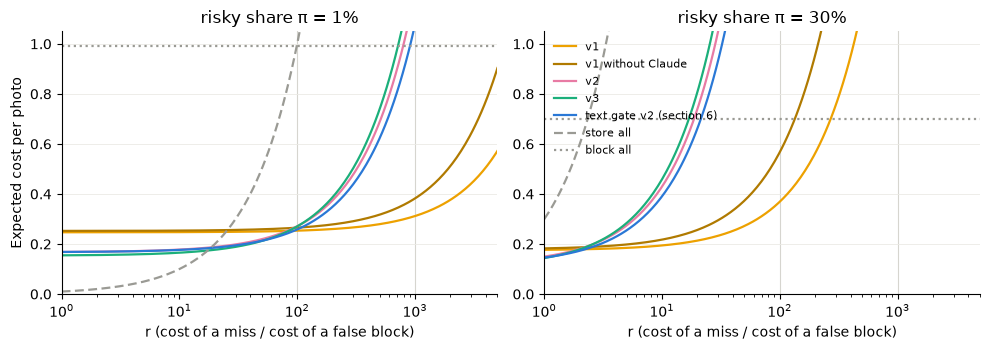

,π = 1%,π = 30%
r = 1,store all,v3
r = 4,store all,v1
r = 10,store all,v1
r = 30,v3,v1
r = 100,v1,v1
r = 1000,v1,block all


In [23]:
import matplotlib.pyplot as plt

CURVES = {g: BEST[g]["pred"] for g in ["v1", "v1 without Claude", "v2", "v3", "text gate v2 (section 6)"]}
CURVES["store all"], CURVES["block all"] = np.zeros(len(SUB), bool), np.ones(len(SUB), bool)
RT = {g: {"FNR": 1 - p[T_I][YR[T_I]].mean(), "FPR": p[T_I][~YR[T_I]].mean()} for g, p in CURVES.items()}
COL = {"v1": "#eda100", "v1 without Claude": "#b07a00", "v2": "#e87ba4", "v3": "#1baf7a", "text gate v2 (section 6)": "#2a78d6"}
rs = np.logspace(0, 3.7, 300)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=False)
for ax, pi in zip(axes, [0.01, YR[T_I].mean()]):
    for g, q in RT.items():
        ref = g not in COL
        ax.plot(rs, [pi * r * q["FNR"] + (1 - pi) * q["FPR"] for r in rs], lw=1.6, label=g, color="#9a9a94" if ref else COL[g],
                ls=(0, (4, 2)) if g == "store all" else ":" if ref else "-")
    for r in (100, 1000):
        ax.axvline(r, color="#d6d5cf", lw=0.8, zorder=0)
    ax.set(xscale="log", xlim=(1, rs[-1]), ylim=(0, 1.05), xlabel="r (cost of a miss / cost of a false block)",
           title=f"risky share π = {pi:.0%}")
    ax.grid(axis="y", color="#ebeae5", lw=0.6)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Expected cost per photo")
axes[1].legend(frameon=False, fontsize=8, loc="upper left")
fig.tight_layout()
fig.savefig(OUT + "fig_cost_vs_r.png", dpi=200)
plt.show()
lowest = lambda pi, r: min(RT, key=lambda g: pi * r * RT[g]["FNR"] + (1 - pi) * RT[g]["FPR"])
pd.DataFrame({f"π = {pi:.0%}": {f"r = {r}": lowest(pi, r) for r in (1, 4, 10, 30, 100, 1000)} for pi in (0.01, round(float(YR[T_I].mean()), 2))})

In [24]:
s = json.load(open(OUT + "scores.json"))
s["T9"] = T9.reset_index().rename(columns={"index": "gate"}).to_dict("records")
s["picks9"] = {g: {"ocr": list(k["ocr"]), "blocks": list(k["blocks"])} for g, k in BEST.items()}
json.dump(s, open(OUT + "scores.json", "w"), indent=1, default=str)